In [16]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("../experiments/day3"); OUT.mkdir(parents=True, exist_ok=True)
FIG = Path("../docs"); FIG.mkdir(exist_ok=True)
LEVELS = {"50%": 0.5, "80%": 0.2, "90%": 0.1}      # name: alpha

In [17]:
P = pd.read_csv("../data/processed/preds_cal_test_v1.csv", parse_dates=["od_start_time"])
cal  = P[P["pile"] == "cal"].copy().reset_index(drop=True)
test = P[P["pile"] == "test"].copy().reset_index(drop=True)
for d in (cal, test):
    d["resid"] = d["y_ratio"] - d["pred_ratio"]

print("rows:", len(cal), len(test))
print("missing:", int(P[["y_ratio", "pred_ratio"]].isna().sum().sum()))
print("MAE cal:", round(cal["resid"].abs().mean(), 4), "| test:", round(test["resid"].abs().mean(), 4))

rows: 5441 5307
missing: 0
MAE cal: 0.6288 | test: 0.7195


count    5441.000
mean        0.257
std         1.917
min       -25.449
1%         -1.588
5%         -0.701
25%        -0.213
50%        -0.014
75%         0.287
95%         1.876
99%         5.857
max        41.565
Name: resid, dtype: float64


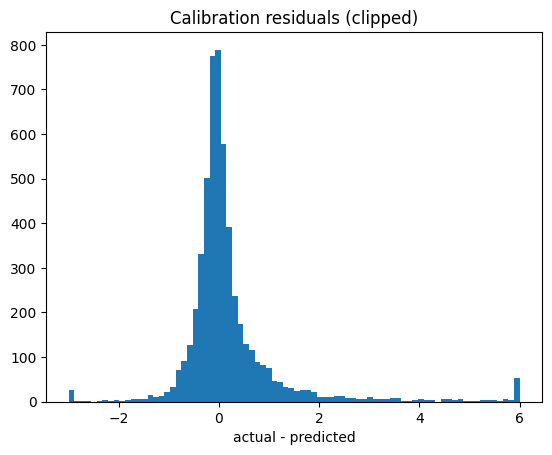

In [18]:
print(cal["resid"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3))
plt.hist(cal["resid"].clip(-3, 6), bins=80); plt.title("Calibration residuals (clipped)")
plt.xlabel("actual - predicted"); plt.show()

In [19]:
def q_abs(scores, alpha):
    """Symmetric margin: covers (1-alpha) of absolute mistakes."""
    s = np.sort(scores)
    n = len(s)
    k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return s[k - 1]

def q_signed(resid, alpha):
    """Asymmetric margins: alpha/2 allowed below, alpha/2 above."""
    s = np.sort(resid)
    n = len(s)
    k_hi = min(int(np.ceil((n + 1) * (1 - alpha / 2))), n)
    k_lo = max(int(np.floor((n + 1) * alpha / 2)), 1)
    return s[k_lo - 1], s[k_hi - 1]

def interval_metrics(y, lo, hi, osrm, alpha):
    inside = (y >= lo) & (y <= hi)
    width = hi - lo
    score = width + (2 / alpha) * np.clip(lo - y, 0, None) + (2 / alpha) * np.clip(y - hi, 0, None)
    return {
        "coverage": float(inside.mean()),
        "mean_width": float(width.mean()),
        "median_width": float(np.median(width)),
        "mean_width_min": float((width * osrm).mean()),
        "interval_score": float(score.mean())
    }

In [20]:
rows = []
y = test["y_ratio"].to_numpy()
osrm = test["osrm_time_min"].to_numpy()

for name, a in LEVELS.items():
    q = q_abs(cal["resid"].abs().to_numpy(), a)
    lo = np.clip(test["pred_ratio"].to_numpy() - q, 0, None)
    hi = test["pred_ratio"].to_numpy() + q
    rows.append({
        "method": "A symmetric",
        "level": name,
        "target": 1 - a,
        **interval_metrics(y, lo, hi, osrm, a)
    })

resA = pd.DataFrame(rows).round(3)
display(resA)

,method,level,target,coverage,mean_width,median_width,mean_width_min,interval_score
0,A symmetric,50%,0.5,0.442,0.470,0.470,40.840,2.632
1,A symmetric,80%,0.8,0.772,1.345,1.345,116.764,5.192
2,A symmetric,90%,0.9,0.884,2.374,2.378,206.187,8.414


In [21]:
rows = []
for name, a in LEVELS.items():
    r_lo, r_hi = q_signed(cal["resid"].to_numpy(), a)
    lo = np.clip(test["pred_ratio"].to_numpy() + r_lo, 0, None)
    hi = test["pred_ratio"].to_numpy() + r_hi
    rows.append({
        "method": "B asymmetric",
        "level": name,
        "target": 1 - a,
        **interval_metrics(y, lo, hi, osrm, a),
        "lo_offset": r_lo,
        "hi_offset": r_hi
    })

resB = pd.DataFrame(rows).round(3)
display(pd.concat([resA, resB], ignore_index=True))

,method,level,target,coverage,mean_width,median_width,mean_width_min,interval_score,lo_offset,hi_offset
0,A symmetric,50%,0.5,0.442,0.470,0.470,40.840,2.632,NaN,NaN
1,A symmetric,80%,0.8,0.772,1.345,1.345,116.764,5.192,NaN,NaN
2,A symmetric,90%,0.9,0.884,2.374,2.378,206.187,8.414,NaN,NaN
3,B asymmetric,50%,0.5,0.445,0.501,0.501,43.478,2.631,-0.214,0.287
4,B asymmetric,80%,0.8,0.747,1.464,1.464,127.044,5.094,-0.462,1.002
5,B asymmetric,90%,0.9,0.873,2.582,2.582,224.105,7.914,-0.703,1.879


In [22]:
cs = cal.sort_values("od_start_time").reset_index(drop=True)
h = len(cs) // 2
early, late = cs.iloc[:h], cs.iloc[h:]

for name, a in LEVELS.items():
    qa = q_abs(early["resid"].abs().to_numpy(), a)
    covA = ((late["resid"].abs()) <= qa).mean()
    
    r_lo, r_hi = q_signed(early["resid"].to_numpy(), a)
    covB = ((late["resid"] >= r_lo) & (late["resid"] <= r_hi)).mean()
    
    print(f"Level {name}: target {1-a:.2f} | A coverage {covA:.3f} | B coverage {covB:.3f}")

Level 50%: target 0.50 | A coverage 0.498 | B coverage 0.501
Level 80%: target 0.80 | A coverage 0.810 | B coverage 0.808
Level 90%: target 0.90 | A coverage 0.903 | B coverage 0.909


In [23]:
def coverage_ci(inside, trips, n=2000, seed=0):
    g = pd.DataFrame({"t": trips, "x": inside.astype(float)}).groupby("t")["x"].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    rng = np.random.default_rng(seed)
    b = [s[i].sum() / c[i].sum() for i in (rng.integers(0, len(g), len(g)) for _ in range(n))]
    return np.percentile(b, [2.5, 97.5]).round(3)

for name, a in LEVELS.items():
    r_lo, r_hi = q_signed(cal["resid"].to_numpy(), a)
    lo = test["pred_ratio"] + r_lo
    hi = test["pred_ratio"] + r_hi
    inside = ((test["y_ratio"] >= lo) & (test["y_ratio"] <= hi)).to_numpy()
    print(name, "coverage:", round(inside.mean(), 3), "95% CI:", coverage_ci(inside, test["trip_uuid"].to_numpy()))

50% coverage: 0.445 95% CI: [0.43  0.459]
80% coverage: 0.747 95% CI: [0.735 0.759]
90% coverage: 0.873 95% CI: [0.864 0.881]


In [24]:
def add_slices(d, ref):
    d = d.copy()
    e = ref["osrm_distance_km"].quantile([1/3, 2/3]).to_numpy()
    d["dist_bucket"] = pd.cut(d["osrm_distance_km"], [-np.inf, e[0], e[1], np.inf], labels=["short", "medium", "long"])
    d["hist_bucket"] = pd.cut(d["lane_history_count"], [-1, 0, 2, 9, np.inf], labels=["0 (unseen)", "1-2", "3-9", "10+"])
    d["weekend"] = np.where(d["od_start_time"].dt.dayofweek >= 5, "weekend", "weekday")
    d["day"] = d["od_start_time"].dt.date.astype(str)
    return d

cal_s, test_s = add_slices(cal, cal), add_slices(test, cal)

def slice_table(d, lo, hi, cols):
    d = d.assign(inside=(d["y_ratio"] >= lo) & (d["y_ratio"] <= hi), width=hi - lo)
    parts = []
    for c in cols:
        t = d.groupby(c, observed=True).agg(
            n=("inside", "size"),
            coverage=("inside", "mean"),
            mean_width=("width", "mean")
        ).reset_index()
        t.insert(0, "slice", c)
        t = t.rename(columns={c: "group"})
        parts.append(t)
    return pd.concat(parts, ignore_index=True).round(3)

a = LEVELS["90%"]
r_lo, r_hi = q_signed(cal["resid"].to_numpy(), a)
lo9 = np.clip(test_s["pred_ratio"] + r_lo, 0, None)
hi9 = test_s["pred_ratio"] + r_hi

slice_table(test_s, lo9, hi9, ["route_type", "dist_bucket", "hist_bucket", "weekend", "day"])

,slice,group,n,coverage,mean_width
0,route_type,Carting,2705,0.824,2.582
1,route_type,FTL,2602,0.923,2.582
2,dist_bucket,short,1874,0.803,2.582
3,dist_bucket,medium,1772,0.892,2.582
4,dist_bucket,long,1661,0.931,2.582
5,hist_bucket,0 (unseen),434,0.774,2.582
6,hist_bucket,1-2,407,0.835,2.582
7,hist_bucket,3-9,2176,0.890,2.582
8,hist_bucket,10+,2290,0.882,2.582
9,weekend,weekday,3586,0.873,2.582


In [26]:
cal_s["grp"]  = cal_s["route_type"] + "|" + cal_s["dist_bucket"].astype(str)
test_s["grp"] = test_s["route_type"] + "|" + test_s["dist_bucket"].astype(str)

def grouped_bounds(cal_df, alpha, min_n=200):
    glob = q_signed(cal_df["resid"].to_numpy(), alpha)
    table = {g: (q_signed(d["resid"].to_numpy(), alpha) if len(d) >= min_n else glob)
             for g, d in cal_df.groupby("grp")}
    return table, glob

def apply_grouped(df, table, glob):
    off = [table.get(g, glob) for g in df["grp"]]
    lo = np.clip(df["pred_ratio"].to_numpy() + np.array([o[0] for o in off]), 0, None)
    hi = df["pred_ratio"].to_numpy() + np.array([o[1] for o in off])
    return lo, hi

rowsM = []
for name, a in LEVELS.items():
    table, glob = grouped_bounds(cal_s, a)
    lo, hi = apply_grouped(test_s, table, glob)
    rowsM.append({"method": "C grouped (route x distance)", "level": name, "target": 1 - a,
                  **interval_metrics(test_s["y_ratio"].to_numpy(), lo, hi,
                                     test_s["osrm_time_min"].to_numpy(), a)})
pd.DataFrame(rowsM).round(3)

table90, glob90 = grouped_bounds(cal_s, LEVELS["90%"])
lo9m, hi9m = apply_grouped(test_s, table90, glob90)
slice_table(test_s, lo9m, hi9m, ["route_type", "dist_bucket", "hist_bucket"])

,slice,group,n,coverage,mean_width
0,route_type,Carting,2705,0.882,3.704
1,route_type,FTL,2602,0.862,1.681
2,dist_bucket,short,1874,0.874,4.030
3,dist_bucket,medium,1772,0.869,2.381
4,dist_bucket,long,1661,0.874,1.579
5,hist_bucket,0 (unseen),434,0.744,2.249
6,hist_bucket,1-2,407,0.826,2.503
7,hist_bucket,3-9,2176,0.878,2.527
8,hist_bucket,10+,2290,0.899,3.013


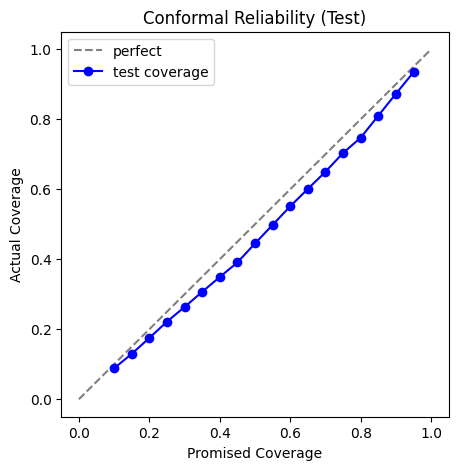

In [27]:
levels = np.arange(0.10, 0.96, 0.05)
emp = []
for lv in levels:
    r_lo, r_hi = q_signed(cal["resid"].to_numpy(), 1 - lv)
    inside = (test["y_ratio"] >= test["pred_ratio"] + r_lo) & (test["y_ratio"] <= test["pred_ratio"] + r_hi)
    emp.append(inside.mean())

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", label="perfect", color="gray")
plt.plot(levels, emp, marker="o", label="test coverage", color="blue")
plt.xlabel("Promised Coverage")
plt.ylabel("Actual Coverage")
plt.legend()
plt.title("Conformal Reliability (Test)")
plt.savefig(FIG / "conformal_reliability_v1.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
a = LEVELS["90%"]
r_lo, r_hi = q_signed(cal["resid"].to_numpy(), a)
test_out = test.copy()
for name, al in LEVELS.items():
    r_lo, r_hi = q_signed(cal["resid"].to_numpy(), al)
    tag = name.replace("%", "")
    test_out[f"lo{tag}"] = np.clip(test_out["pred_ratio"] + r_lo, 0, None)
    test_out[f"hi{tag}"] = test_out["pred_ratio"] + r_hi
    test_out[f"excess_lo{tag}_min"] = (test_out[f"lo{tag}"] - 1) * test_out["osrm_time_min"]
    test_out[f"excess_hi{tag}_min"] = (test_out[f"hi{tag}"] - 1) * test_out["osrm_time_min"]
test_out["pred_excess_min"] = (test_out["pred_ratio"] - 1) * test_out["osrm_time_min"]
test_out.head()

,trip_uuid,source_center,destination_center,route_type,od_start_time,osrm_time_min,osrm_distance_km,lane_history_count,y_ratio,base_pred,...,excess_hi50_min,lo80,hi80,excess_lo80_min,excess_hi80_min,lo90,hi90,excess_lo90_min,excess_hi90_min,pred_excess_min
0,trip-153817420257110897,IND121004AAB,IND000000ACB,Carting,2018-09-28 22:36:42.571355,63.0,75.9685,20,1.650794,1.869231,...,69.250888,1.350039,2.813543,22.052432,114.253239,1.109453,3.691063,6.895512,169.536941,51.153808
1,trip-153817425629451735,IND712311AAA,IND834002AAB,FTL,2018-09-28 22:37:36.294770,279.0,391.4511,10,2.347670,2.447566,...,468.484081,1.929973,3.393477,259.462350,667.780208,1.689387,4.270997,192.338843,912.608031,388.339872
2,trip-153817425629451735,IND834002AAB,IND000000ACB,FTL,2018-09-29 12:07:44.347459,852.0,1162.3098,5,1.961268,2.035170,...,1117.727044,1.562704,3.026209,479.424124,1726.330273,1.322118,3.903728,274.444814,2473.976528,872.985589
3,trip-153817438822669272,IND147101AAA,IND147105AAA,FTL,2018-09-29 02:11:12.383847,23.0,25.8111,4,1.391304,1.456522,...,17.172413,0.997445,2.460950,-0.058769,33.601843,0.756859,3.338469,-5.592248,53.784782,10.565543
4,trip-153817485421599770,IND600016AAC,IND600119AAA,Carting,2018-09-28 22:47:34.216240,33.0,35.4745,5,1.181818,2.333333,...,43.825719,1.578870,3.042375,19.102719,67.398379,1.338284,3.919894,11.163379,96.356509,34.346297


In [29]:
params = {
    "model": "residual_xgb_plain_v1",
    "calibration_pile": "data/datasplit/calibration_legs_v1.csv",
    "calibration_legs": int(len(cal)),
    "method": "split conformal on signed residuals (asymmetric, finite-sample corrected)",
    "levels": {name: {"alpha": al,
                      "lo_offset": float(q_signed(cal["resid"].to_numpy(), al)[0]),
                      "hi_offset": float(q_signed(cal["resid"].to_numpy(), al)[1])}
               for name, al in LEVELS.items()},
}
paths = {"params": OUT / "conformal_params_v1.json",
         "test": Path("../data/processed/preds_test_intervals_v1.csv"),
         "compare": OUT / "interval_comparison_v1.csv"}
for p in paths.values():
    assert not p.exists(), f"{p} already exists, choose a new version"

with open(paths["params"], "w") as f: json.dump(params, f, indent=2)
test_out.to_csv(paths["test"], index=False)
pd.concat([resA, resB, pd.DataFrame(rowsM).round(3)]).to_csv(paths["compare"], index=False)
print("saved")

saved


In [30]:
keys = ["trip_uuid", "source_center", "destination_center"]
ends = pd.concat([
    pd.read_csv("../data/datasplit/calibration_legs_v1.csv", usecols=keys + ["od_end_time"]),
    pd.read_csv("../data/datasplit/test_legs_v1.csv",        usecols=keys + ["od_end_time"]),
]).drop_duplicates(subset=keys)

allp = pd.concat([cal, test], ignore_index=True).merge(ends, on=keys, how="left")
allp["end_ts"] = pd.to_datetime(allp["od_end_time"], format="mixed")
allp["day"] = allp["od_start_time"].dt.normalize()
print("rows ok:", len(allp) == len(cal) + len(test), "| missing end time:", int(allp["end_ts"].isna().sum()))

def rolling_coverage(alpha, window=None):
    t = allp[allp["pile"] == "test"]
    inside, widths = [], []
    for day, d in t.groupby("day"):
        pool = allp[allp["end_ts"] < day]               # only legs finished before this day
        if window:
            pool = pool.sort_values("end_ts").tail(window)
        r_lo, r_hi = q_signed(pool["resid"].to_numpy(), alpha)
        lo = np.clip(d["pred_ratio"].to_numpy() + r_lo, 0, None)
        hi = d["pred_ratio"].to_numpy() + r_hi
        inside.append(((d["y_ratio"].to_numpy() >= lo) & (d["y_ratio"].to_numpy() <= hi)))
        widths.append(hi - lo)
    return np.concatenate(inside).mean(), np.concatenate(widths).mean()

rows = []
static_cov = resB.set_index("level")["coverage"]
for name, a in LEVELS.items():
    c_all, w_all = rolling_coverage(a)
    c_win, w_win = rolling_coverage(a, window=3000)
    rows.append({"level": name, "target": 1 - a, "static (B)": static_cov[name],
                 "rolling, all finished": c_all, "width": w_all,
                 "rolling, last 3000": c_win, "width (3000)": w_win})
pd.DataFrame(rows).round(3)

rows ok: True | missing end time: 0


,level,target,static (B),"rolling, all finished",width,"rolling, last 3000",width (3000)
0,50%,0.5,0.445,0.464,0.522,0.484,0.550
1,80%,0.8,0.747,0.765,1.551,0.782,1.657
2,90%,0.9,0.873,0.882,2.721,0.893,2.903


In [31]:
cal_d, test_d = cal_s.copy(), test_s.copy()
for d in (cal_d, test_d):
    d["lowhist"] = np.where(d["lane_history_count"] < 3, "low", "ok")
    d["grp"] = d["route_type"] + "|" + d["dist_bucket"].astype(str) + "|" + d["lowhist"]

rowsD = []
for name, a in LEVELS.items():
    table, glob = grouped_bounds(cal_d, a, min_n=100)
    lo, hi = apply_grouped(test_d, table, glob)
    rowsD.append({"method": "D grouped (route x distance x history)", "level": name,
                  "target": 1 - a,
                  **interval_metrics(test_d["y_ratio"].to_numpy(), lo, hi,
                                     test_d["osrm_time_min"].to_numpy(), a)})
display(pd.DataFrame(rowsD).round(3))

table90, glob90 = grouped_bounds(cal_d, LEVELS["90%"], min_n=100)
lo9d, hi9d = apply_grouped(test_d, table90, glob90)
slice_table(test_d, lo9d, hi9d, ["route_type", "dist_bucket", "hist_bucket"])

,method,level,target,coverage,mean_width,median_width,mean_width_min,interval_score
0,D grouped (route x distance x history),50%,0.5,0.455,0.575,0.501,36.581,2.601
1,D grouped (route x distance x history),80%,0.8,0.756,1.504,1.464,94.350,4.931
2,D grouped (route x distance x history),90%,0.9,0.865,2.621,2.582,166.446,7.578


,slice,group,n,coverage,mean_width
0,route_type,Carting,2705,0.862,3.367
1,route_type,FTL,2602,0.868,1.846
2,dist_bucket,short,1874,0.847,3.605
3,dist_bucket,medium,1772,0.863,2.333
4,dist_bucket,long,1661,0.886,1.819
5,hist_bucket,0 (unseen),434,0.797,2.980
6,hist_bucket,1-2,407,0.835,2.856
7,hist_bucket,3-9,2176,0.860,2.338
8,hist_bucket,10+,2290,0.887,2.781


In [32]:
final_cal, final_test, MIN_N = cal_s, test_s, 200      # Method C
# for Method D use: final_cal, final_test, MIN_N = cal_d, test_d, 100

edges = [float(x) for x in cal["osrm_distance_km"].quantile([1/3, 2/3])]

levels_out, test_final = {}, test.copy()
for name, al in LEVELS.items():
    table, glob = grouped_bounds(final_cal, al, MIN_N)
    lo, hi = apply_grouped(final_test, table, glob)
    tag = name.replace("%", "")
    test_final[f"lo{tag}"], test_final[f"hi{tag}"] = lo, hi
    test_final[f"excess_lo{tag}_min"] = (lo - 1) * test_final["osrm_time_min"]
    test_final[f"excess_hi{tag}_min"] = (hi - 1) * test_final["osrm_time_min"]
    levels_out[name] = {
        "alpha": al,
        "global_offsets": [float(glob[0]), float(glob[1])],
        "group_offsets": {g: [float(v[0]), float(v[1])] for g, v in table.items()},
    }
test_final["pred_excess_min"] = (test_final["pred_ratio"] - 1) * test_final["osrm_time_min"]
test_final["grp"] = final_test["grp"].to_numpy()

params2 = {
    "model": "residual_xgb_plain_v1",
    "method": "grouped (Mondrian) split conformal on signed residuals, asymmetric, finite-sample corrected",
    "groups": "route_type | distance tercile (edges from calibration) [| lane history low/ok if method D]",
    "distance_edges_km": edges,
    "min_group_size": MIN_N,
    "calibration_legs": int(len(cal)),
    "levels": levels_out,
}

paths2 = {"params": OUT / "conformal_params_v2.json",
          "test": Path("../data/processed/preds_test_intervals_v2.csv"),
          "compare": OUT / "interval_comparison_v2.csv"}
for p in paths2.values():
    assert not p.exists(), f"{p} already exists, choose a new version"

with open(paths2["params"], "w") as f: json.dump(params2, f, indent=2)
test_final.to_csv(paths2["test"], index=False)
all_cmp = [resA, resB, pd.DataFrame(rowsM).round(3)]
# all_cmp.append(pd.DataFrame(rowsD).round(3))     # if you ran Step 2
pd.concat(all_cmp, ignore_index=True).to_csv(paths2["compare"], index=False)
print("saved v2")

saved v2


In [33]:
p = json.load(open(OUT / "conformal_params_v2.json"))
print("min_group_size:", p["min_group_size"])
print(list(p["levels"]["90%"]["group_offsets"].keys()))

min_group_size: 200
['Carting|long', 'Carting|medium', 'Carting|short', 'FTL|long', 'FTL|medium', 'FTL|short']


In [34]:
allp_s = add_slices(allp, cal)
allp_s["grp"] = allp_s["route_type"] + "|" + allp_s["dist_bucket"].astype(str)

def rolling_grouped(alpha, window=3000, min_n=200):
    t = allp_s[allp_s["pile"] == "test"]
    ys, los, his, osr = [], [], [], []
    for day, d in t.groupby("day"):                      # "day" is a text date here
        pool = allp_s[allp_s["end_ts"] < pd.Timestamp(day)].sort_values("end_ts").tail(window)
        table, glob = grouped_bounds(pool, alpha, min_n)
        lo, hi = apply_grouped(d, table, glob)
        ys.append(d["y_ratio"].to_numpy()); los.append(lo); his.append(hi)
        osr.append(d["osrm_time_min"].to_numpy())
    return interval_metrics(np.concatenate(ys), np.concatenate(los),
                            np.concatenate(his), np.concatenate(osr), alpha)

rowsE = [{"method": "E rolling + grouped (last 3000)", "level": n, "target": 1 - a, **rolling_grouped(a)}
         for n, a in LEVELS.items()]
pd.DataFrame(rowsE).round(3)

,method,level,target,coverage,mean_width,median_width,mean_width_min,interval_score
0,E rolling + grouped (last 3000),50%,0.5,0.481,0.609,0.553,37.078,2.598
1,E rolling + grouped (last 3000),80%,0.8,0.792,1.747,1.617,105.252,4.920
2,E rolling + grouped (last 3000),90%,0.9,0.895,3.064,2.448,193.232,7.591


In [35]:
roll = []
static_cov = resB.set_index("level")["coverage"]
for name, a in LEVELS.items():
    c_all, w_all = rolling_coverage(a)
    c_win, w_win = rolling_coverage(a, window=3000)
    roll.append({"level": name, "target": 1 - a, "static (B)": static_cov[name],
                 "rolling, all finished": c_all, "width": w_all,
                 "rolling, last 3000": c_win, "width (3000)": w_win})
roll_tbl = pd.DataFrame(roll).round(3)

all_methods = pd.concat([resA, resB, pd.DataFrame(rowsM), pd.DataFrame(rowsD),
                         pd.DataFrame(rowsE)], ignore_index=True).round(3)

p_all  = OUT / "interval_comparison_v3_all_methods.csv"
p_roll = OUT / "rolling_recalibration_v1.csv"
for p in (p_all, p_roll):
    if p.exists():
        print("already exists, skipping:", p.name)
all_methods.to_csv(p_all, index=False) if not p_all.exists() else None
roll_tbl.to_csv(p_roll, index=False) if not p_roll.exists() else None
display(all_methods); display(roll_tbl)

,method,level,target,coverage,mean_width,median_width,mean_width_min,interval_score,lo_offset,hi_offset
0,A symmetric,50%,0.5,0.442,0.470,0.470,40.840,2.632,NaN,NaN
1,A symmetric,80%,0.8,0.772,1.345,1.345,116.764,5.192,NaN,NaN
2,A symmetric,90%,0.9,0.884,2.374,2.378,206.187,8.414,NaN,NaN
3,B asymmetric,50%,0.5,0.445,0.501,0.501,43.478,2.631,-0.214,0.287
4,B asymmetric,80%,0.8,0.747,1.464,1.464,127.044,5.094,-0.462,1.002
5,B asymmetric,90%,0.9,0.873,2.582,2.582,224.105,7.914,-0.703,1.879
6,C grouped (route x distance),50%,0.5,0.457,0.581,0.519,35.440,2.601,NaN,NaN
7,C grouped (route x distance),80%,0.8,0.761,1.569,1.393,94.840,4.926,NaN,NaN
8,C grouped (route x distance),90%,0.9,0.872,2.712,2.221,159.709,7.592,NaN,NaN
9,D grouped (route x distance x history),50%,0.5,0.455,0.575,0.501,36.581,2.601,NaN,NaN


,level,target,static (B),"rolling, all finished",width,"rolling, last 3000",width (3000)
0,50%,0.5,0.445,0.464,0.522,0.484,0.550
1,80%,0.8,0.747,0.765,1.551,0.782,1.657
2,90%,0.9,0.873,0.882,2.721,0.893,2.903


In [36]:
fig_path = FIG / "conformal_reliability_v1.png"
print(fig_path, "exists:", fig_path.exists())

..\docs\conformal_reliability_v1.png exists: True


# Day 3 Conclusions: Conformal Prediction Intervals

## Setup
- Frozen model: residual XGBoost (lane median + learned correction), `residual_xgb_plain_v1`.
- Calibration pile: 5,441 legs (MAE ratio 0.6288). Test pile: 5,307 legs (MAE ratio 0.7195).
- Target: delay ratio = actual time / OSRM time. Intervals are built on the ratio and converted to
  excess minutes as (ratio - 1) x OSRM time.
- Levels: 50%, 80%, 90% (alpha = 0.5, 0.2, 0.1), finite-sample corrected split conformal.

## Why asymmetric intervals
Calibration residuals (actual - predicted) are strongly right-skewed: median -0.01, 5th percentile -0.70,
95th percentile +1.88, 99th percentile +5.86. Late legs can be far later than predicted, so a longer
upper margin is needed.

## Methods compared (test pile)
| Method | Coverage 50/80/90% | Mean width, minutes 50/80/90% | Interval score 50/80/90% |
|---|---|---|---|
| A symmetric | 0.442 / 0.772 / 0.884 | 40.8 / 116.8 / 206.2 | 2.632 / 5.192 / 8.414 |
| B asymmetric | 0.445 / 0.747 / 0.873 | 43.5 / 127.0 / 224.1 | 2.631 / 5.094 / 7.914 |
| **C grouped (route type x distance tercile)** | 0.457 / 0.761 / 0.872 | **35.4 / 94.8 / 159.7** | 2.601 / 4.926 / 7.592 |
| D grouped + lane-history flag | 0.455 / 0.756 / 0.865 | 36.6 / 94.4 / 166.4 | 2.601 / 4.931 / 7.578 |
| E rolling + grouped (last 3,000 finished legs) | **0.481 / 0.792 / 0.895** | 37.1 / 105.3 / 193.2 | 2.598 / 4.920 / 7.591 |

## Main findings
1. **Static grouped conformal (C) is the saved final method.** It has the best interval score among
   the static methods and, at 90%, intervals about 30% narrower in minutes than B (160 vs 224 min) at
   similar coverage. Separate margins for FTL/Carting and short/medium/long legs equalise coverage
   across groups (0.86 to 0.88 at 90%).
2. **Coverage on the test pile is 3 to 4 points below target** for all static methods. Trip-bootstrap
   95% intervals for B exclude the targets (e.g. 90%: 0.873, interval [0.864, 0.881]).
3. **The shortfall is a calibration-age effect, not a method error.** A time-split check inside the
   calibration pile was on target (A: 0.498 / 0.810 / 0.903; B: 0.501 / 0.808 / 0.909). Test legs are

   harder (MAE 0.7195 vs 0.6288) and include more unseen lanes (8.2% vs 4.4% of legs).
   Daily coverage inside the test period is flat (about 0.86 to 0.88), pointing to a level shift
   between the calibration and test weeks rather than a trend.
4. **Rolling recalibration repairs most of the gap.** Refreshing margins with the most recent 3,000
   finished legs raised B's coverage from 0.445 / 0.747 / 0.873 to 0.484 / 0.782 / 0.893, and the
   grouped version (E) reached 0.481 / 0.792 / 0.895, at an interval score equal to C but with
   intervals about 5% / 11% / 21% wider in minutes.
5. **Lane history matters.** Unseen lanes are the weakest group (90% coverage 0.774 for B, 0.744 for C).
   Adding a low-history flag to the groups (D) raised unseen-lane coverage to 0.797 but lowered
   coverage on known lanes, with no overall interval-score gain, so C was kept.
6. The reliability curve lies slightly below the diagonal at every level (largest gap in the middle
   levels), i.e. static intervals are mildly over-confident on the test period.

## Limitations
- Data covers about three weeks (Sep to Oct 2018), one season, with a single calibration/test split.
- Legs within a trip are correlated, so effective sample sizes are smaller than leg counts.
- 2.1% to 4.6% of training legs finish after the next pile begins (mild temporal overlap, not removed).
- Rolling recalibration uses outcomes of earlier test-period legs to refresh margins for later days
  (the model itself stays frozen); this assumes outcomes become available after legs finish.
- Weather features are not used yet (weather data covers only a 7,817-leg core subset).
- Margins live on the delay-ratio scale; converting to minutes assumes the ratio scales with OSRM time.

## Deliverables
- `data/processed/preds_cal_test_v1.csv`, `data/processed/preds_test.csv` (point predictions)
- `data/processed/preds_test_intervals_v1.csv` (method B), `preds_test_intervals_v2.csv` (method C, final)
- `experiments/day3/conformal_params_v1.json` (B), `conformal_params_v2.json` (C with group margins and
  distance cut-points), `interval_comparison_v1.csv`, `interval_comparison_v2.csv`,
  `interval_comparison_v3_all_methods.csv`, `rolling_recalibration_v1.csv`
- `docs/conformal_reliability_v1.png`

## Next
Day 4: cascade simulator (hub failure, load redistribution, overflow rounds) on Person C's 8-node toy graph,

then on Person A's core network; later `risk_table.csv` and `models/risk.py` using the saved C margins.